# 01 · Data validation & EDA
UCI **Paddy Dataset** (id 1186, DOI 10.24432/C55W3J, CC BY 4.0). This notebook validates the raw file, identifies target / feature types and runs the leakage diagnostics that shape every later decision.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
from src import config
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
M, F = config.METRICS_DIR, config.FIG_DIR
show = lambda name, w=900: display(Image(filename=str(F / name), width=w))

In [2]:
from src.data_loader import load_raw, load_clean
raw_orig = load_raw()
raw = load_clean()
print(raw.shape)
raw_orig.head()

(2789, 45)


,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutrients_70Days,Pest_60Day(in ml),30DRain( in mm),30DAI(in mm),30_50DRain( in mm),30_50DAI(in mm),51_70DRain(in mm),...,Min temp_D31_D60,Max temp_D31_D60,Min temp_D61_D90,Max temp_D61_D90,Min temp_D91_D120,Max temp_D91_D120,Inst Wind Speed_D1_D30(in Knots),Inst Wind Speed_D31_D60(in Knots),Inst Wind Speed_D61_D90(in Knots),Inst Wind Speed_D91_D120(in Knots),Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
0,6,Cuddalore,CO_43,alluvial,150,75.0,dry,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167.0,...,16.0,30,15.5,31.0,16.0,33.0,4,10,8,10,SW,W,NNW,WSW,72.0,78,88,85,540,35028
1,6,Kurinjipadi,ponmani,clay,150,75.0,wet,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167.0,...,18.5,35,17.0,32.5,16.0,30.5,10,4,10,6,NW,S,SE,SSE,64.6,85,84,87,600,35412
2,6,Panruti,delux ponni,alluvial,150,75.0,dry,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,...,18.0,30,17.5,33.5,18.0,33.0,4,12,4,12,ENE,NE,NNE,W,85.0,96,84,79,600,36300
3,6,Kallakurichi,CO_43,clay,150,75.0,wet,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,...,17.0,32,16.5,31.5,15.5,32.5,8,6,8,6,W,WNW,SE,S,88.5,95,81,84,540,35016
4,6,Sankarapuram,ponmani,alluvial,150,75.0,dry,120,6,240,12,162.78,62.28,90,3600,18.1,21.9,185.6,272.4,166.1,...,17.5,28,18.0,34.0,16.5,35.0,10,12,10,12,SSE,W,SW,NW,72.7,91,83,81,600,34044


## Schema, feature roles and cardinality

In [3]:
from src.validation import schema_report
schema_report(raw)

,dtype,n_missing,n_unique,min,max,role
hectares,int64,0,6,1.00,6.00,numeric feature
agriblock,str,0,6,NaN,NaN,geographic (categorical)
variety,str,0,3,NaN,NaN,categorical feature
soil_type,str,0,2,NaN,NaN,categorical feature
seed_rate_kg,int64,0,6,25.00,150.00,numeric feature
lp_mainfield_t,float64,0,6,12.50,75.00,numeric feature
nursery_type,str,0,2,NaN,NaN,categorical feature
nursery_area_cents,int64,0,6,20.00,120.00,numeric feature
lp_nursery_t,int64,0,6,1.00,6.00,numeric feature
dap_20d,int64,0,6,40.00,240.00,numeric feature


## Validation summary (missing, invalid, duplicates, target)

In [4]:
v = json.loads((M/'validation.json').read_text())
print(json.dumps({k: v[k] for k in ['shape','missing_values_total','invalid_values','duplicates','duplicates_after_dedup']}, indent=1))
pd.DataFrame({'yield_kg': v['target_yield_kg'], 'yield_kg_per_ha (dedup)': v['target_yield_kg_per_ha']})

{
 "shape": [
  2789,
  45
 ],
 "missing_values_total": 0,
 "invalid_values": {
  "negative_values": 0,
  "rh_out_of_0_100": 0,
  "tmin_gt_tmax": 0,
  "zero_or_negative_yield": 0,
  "zero_hectares": 0,
  "unknown_wind_direction_codes": []
 },
 "duplicates": {
  "n_rows": 2789,
  "exact_duplicate_rows": 451,
  "rows_after_dedup": 2338,
  "unique_feature_configurations": 410,
  "configs_with_conflicting_targets": 375
 },
 "duplicates_after_dedup": {
  "n_rows": 2338,
  "exact_duplicate_rows": 0,
  "rows_after_dedup": 2338,
  "unique_feature_configurations": 410,
  "configs_with_conflicting_targets": 375
 }
}


,yield_kg,yield_kg_per_ha (dedup)
count,2789.00,2338.00
mean,22517.73,5985.00
std,9199.66,289.35
min,5410.00,5410.00
25%,16389.00,5780.00
50%,24636.00,5964.00
75%,31035.00,6227.00
max,38814.00,6469.00


## Outliers (1.5×IQR per numeric column, raw data)

In [5]:
pd.read_csv(M/'outlier_counts_iqr.csv', index_col=0).query('n_iqr_outliers > 0')

,n_iqr_outliers
wind_kn_d61_90,425


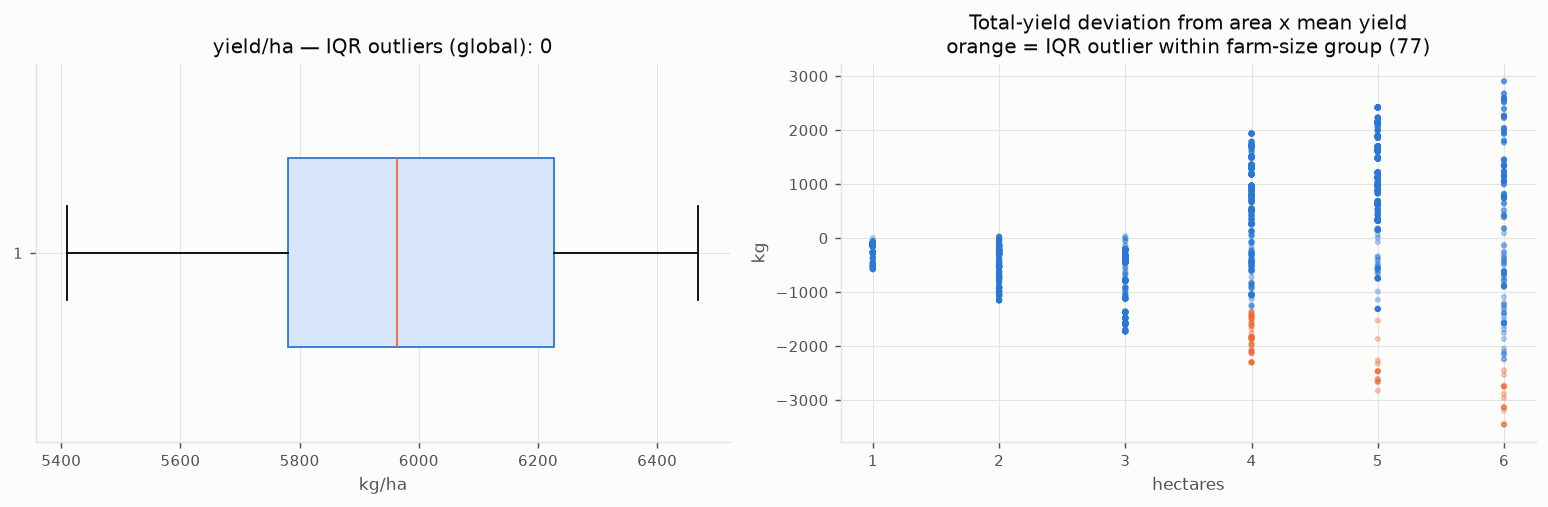

In [6]:
show('eda_outliers.png')

## Leakage & structural diagnostics

In [7]:
leak = json.loads((M/'leakage_report.json').read_text())
print(json.dumps(leak['deduplicated'], indent=1))

{
 "input_qty_unique_values_per_hectare": {
  "seed_rate_kg": 1,
  "lp_mainfield_t": 1,
  "nursery_area_cents": 1,
  "lp_nursery_t": 1,
  "dap_20d": 1,
  "thiobencarb_28d": 1,
  "urea_40d": 1,
  "potash_50d": 1,
  "micronutrients_70d": 1,
  "pesticide_60d_ml": 1
 },
 "corr_yield_kg_vs_hectares": 0.9943389943679958,
 "r2_yield_kg_from_hectares_linear": 0.9887100357207571,
 "corr_trash_vs_yield_kg": 0.9574530982411769,
 "trash_per_ha_by_variety": {
  "CO_43": {
   "90.0": 611
  },
  "delux ponni": {
   "80.0": 831,
   "100.0": 1
  },
  "ponmani": {
   "100.0": 895
  }
 },
 "n_distinct_weather_profiles": 6,
 "weather_cols_determined_by_agriblock": 28,
 "n_weather_cols": 28,
 "rain_plus_ai_unique_per_stage": {
  "d0_30": [
   40.0
  ],
  "d30_50": [
   458.0
  ],
  "d51_70": [
   417.0
  ],
  "d71_105": [
   125.0
  ]
 },
 "temporal_columns_present": [],
 "per_ha_within_config_variance_share": 0.40815671228482403,
 "per_ha_r2_ceiling_estimate": 0.591843287715176,
 "top_corr_with_yield_kg":

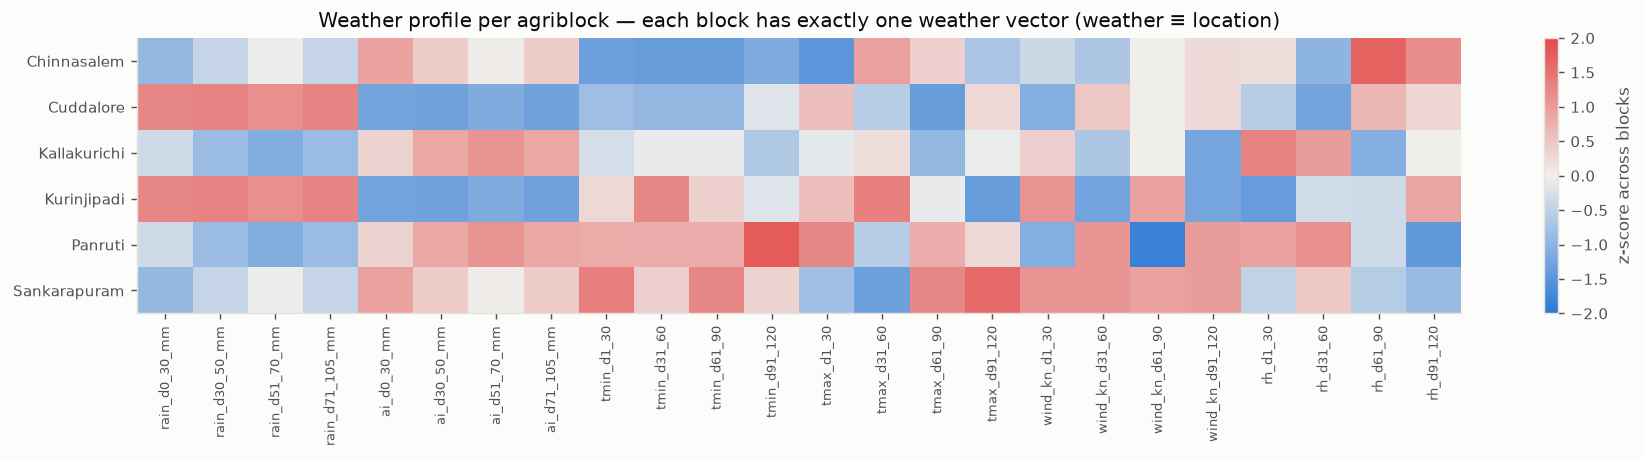

In [8]:
show('eda_weather_by_block.png')

## Target distribution

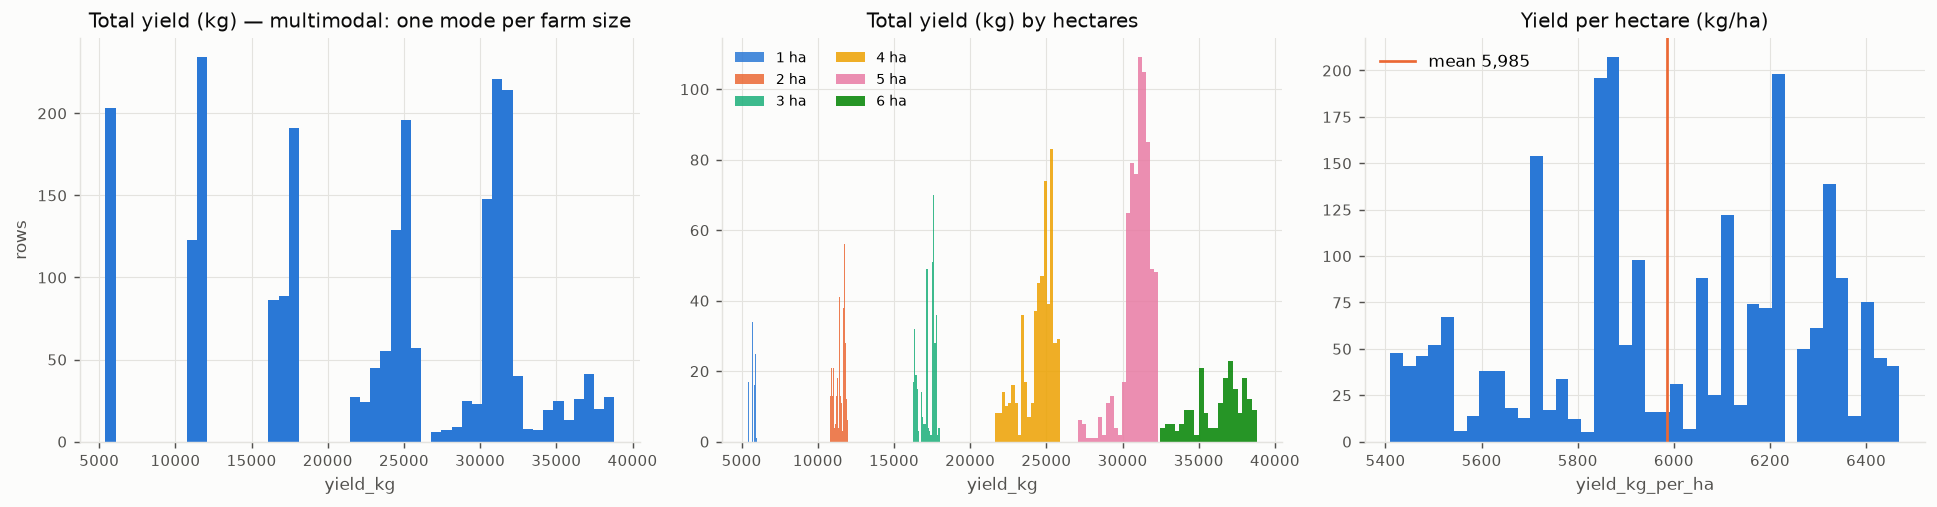

In [9]:
show('eda_target_distribution.png')

## Feature distributions & correlation

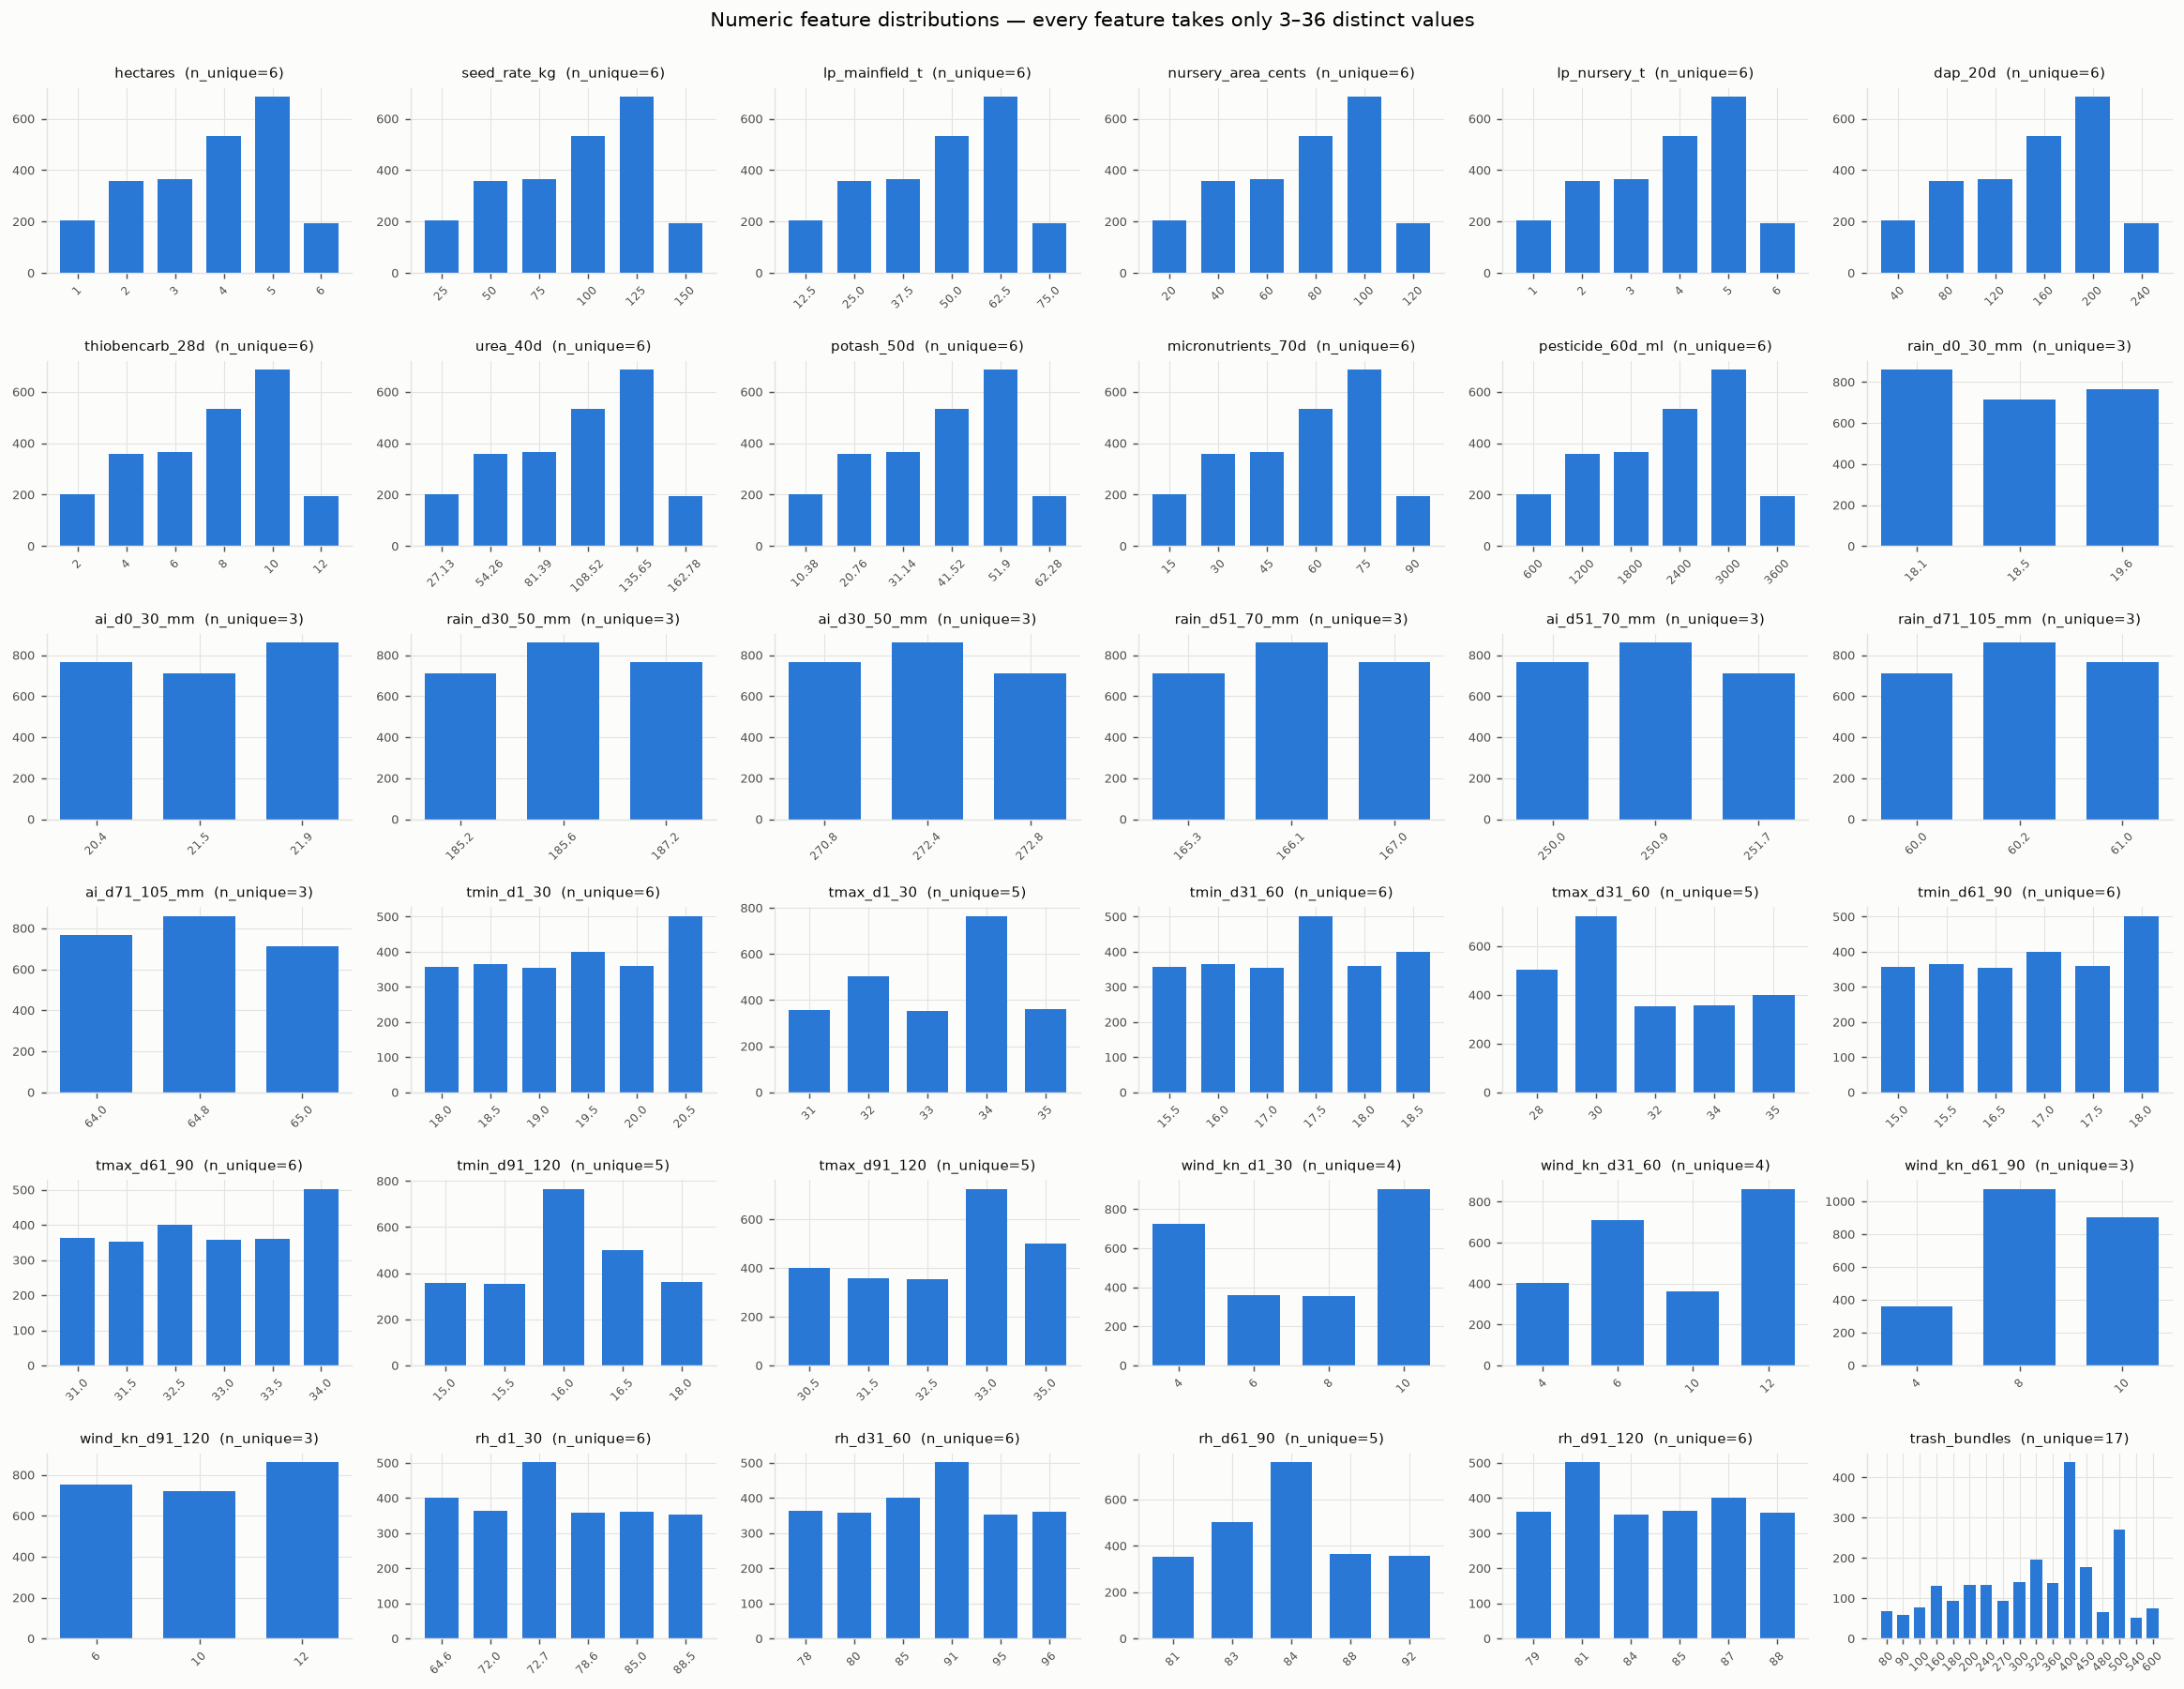

In [10]:
show('eda_feature_distributions.png', 1100)

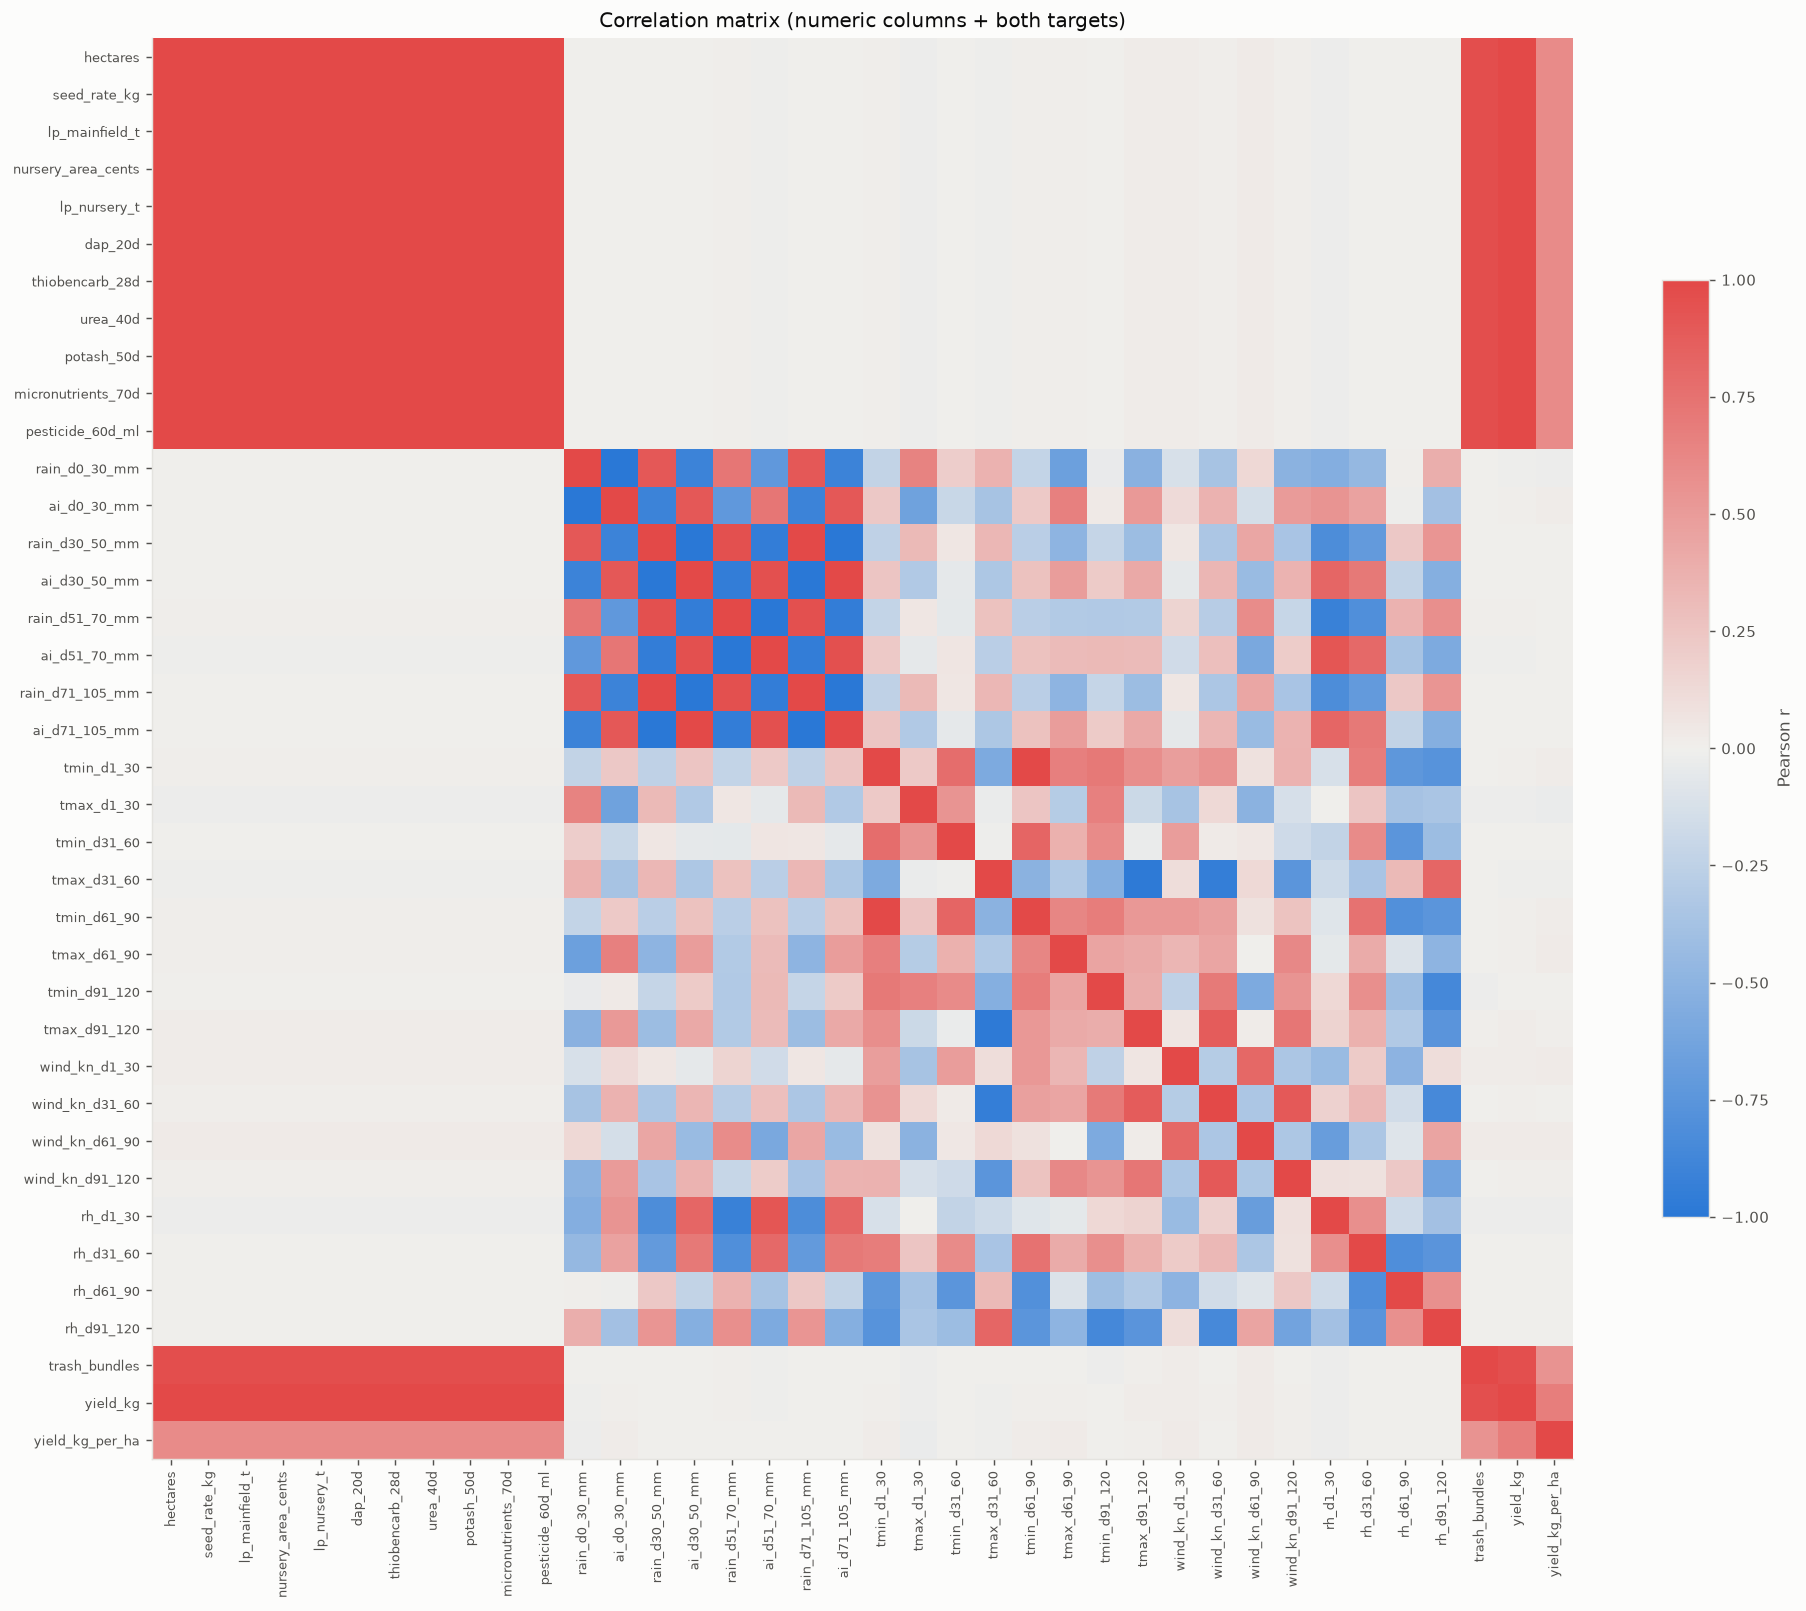

In [11]:
show('eda_correlation_matrix.png', 900)

## Yield vs agronomic variables
Left panels: yield per hectare (jittered strips, group means). Right: total yield coloured by farm size. These are associations only; no causal claim is made.

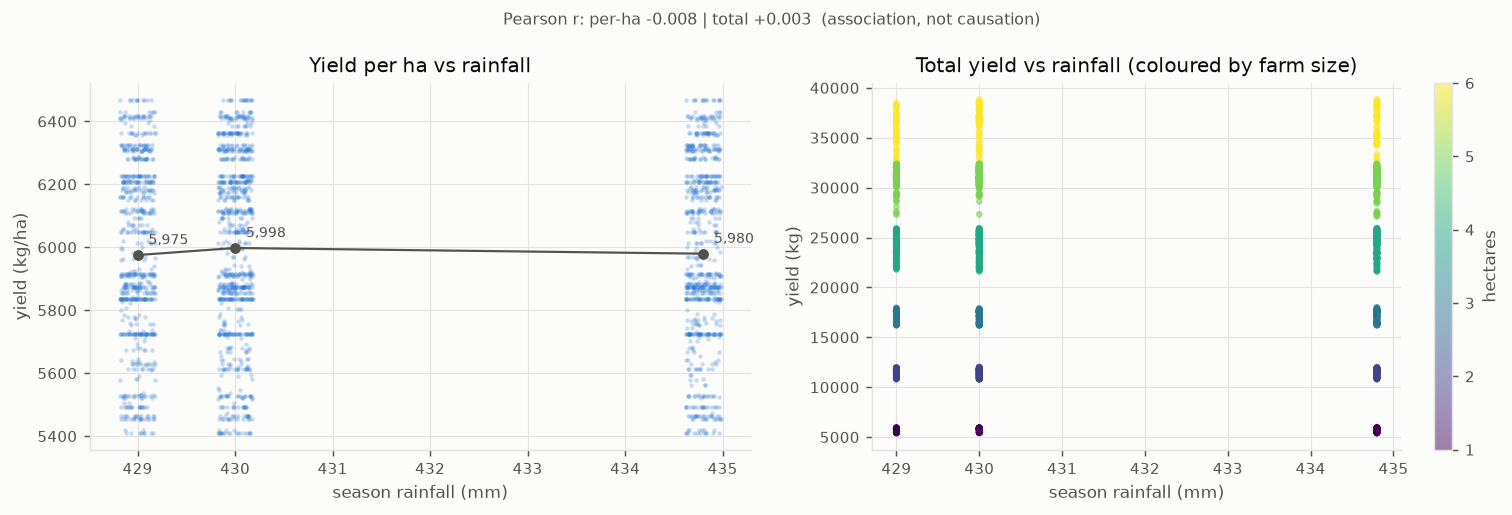

In [12]:
show('eda_yield_vs_rainfall.png')

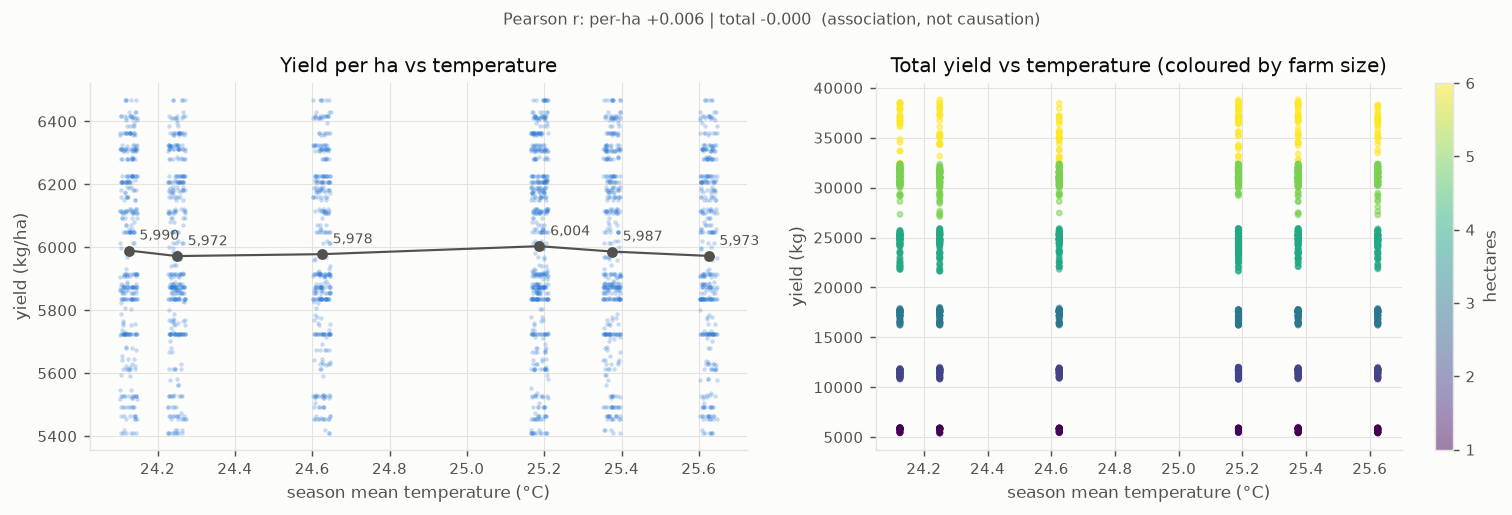

In [13]:
show('eda_yield_vs_temperature.png')

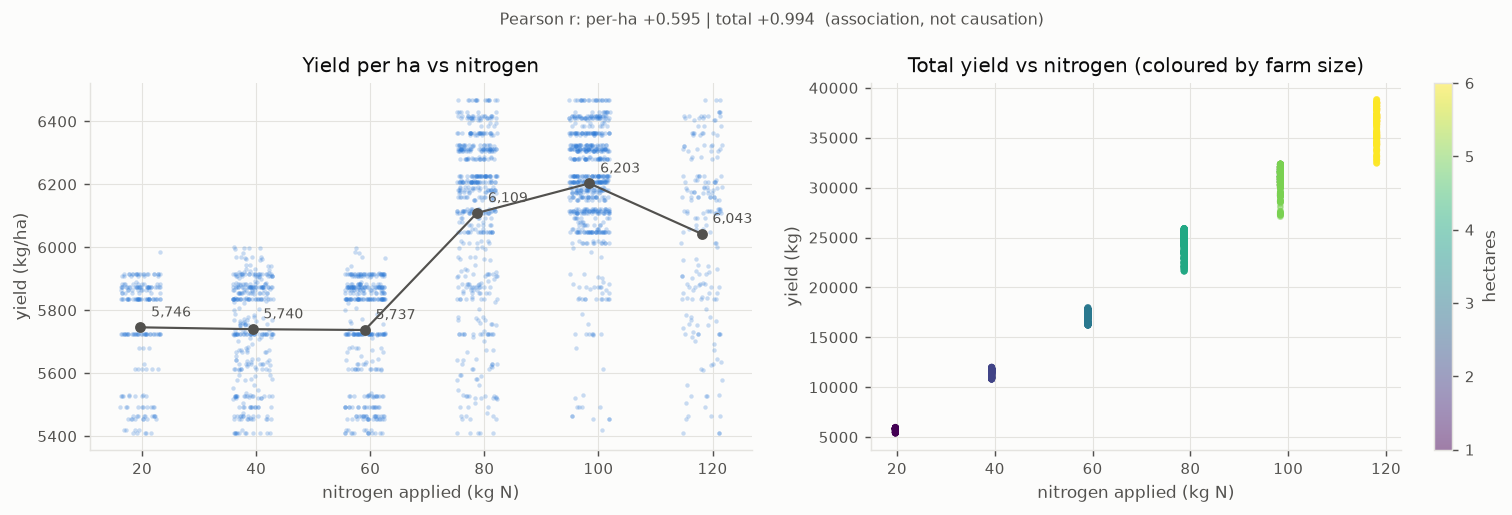

In [14]:
show('eda_yield_vs_nitrogen.png')

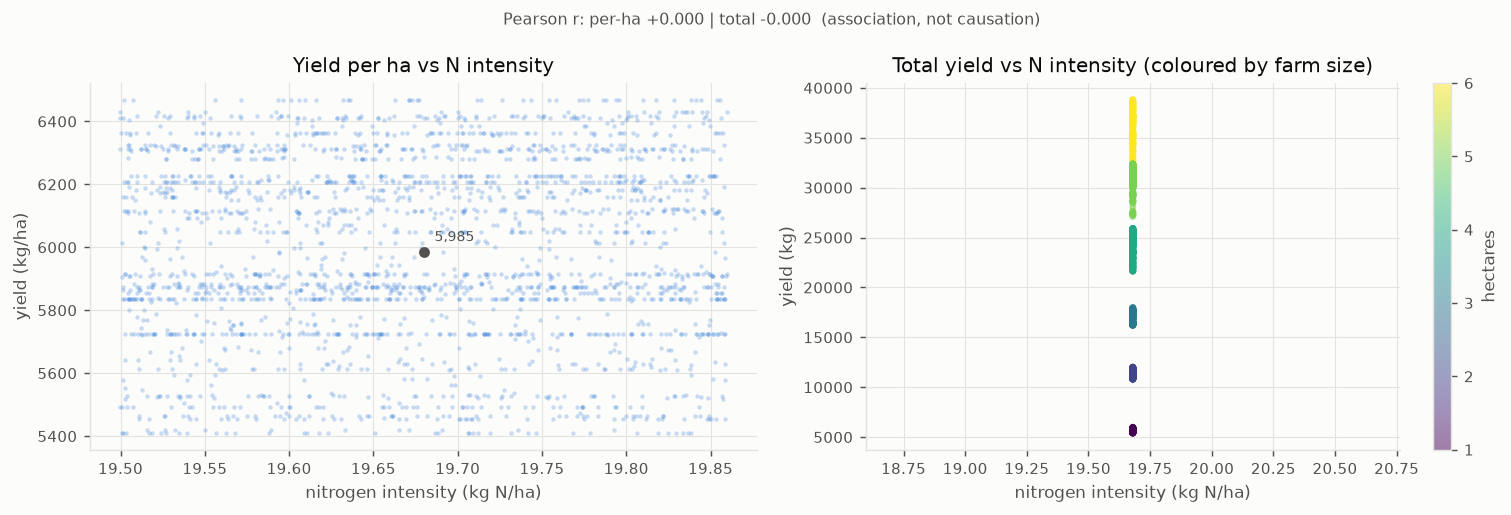

In [15]:
show('eda_yield_vs_nitrogen_per_ha.png')

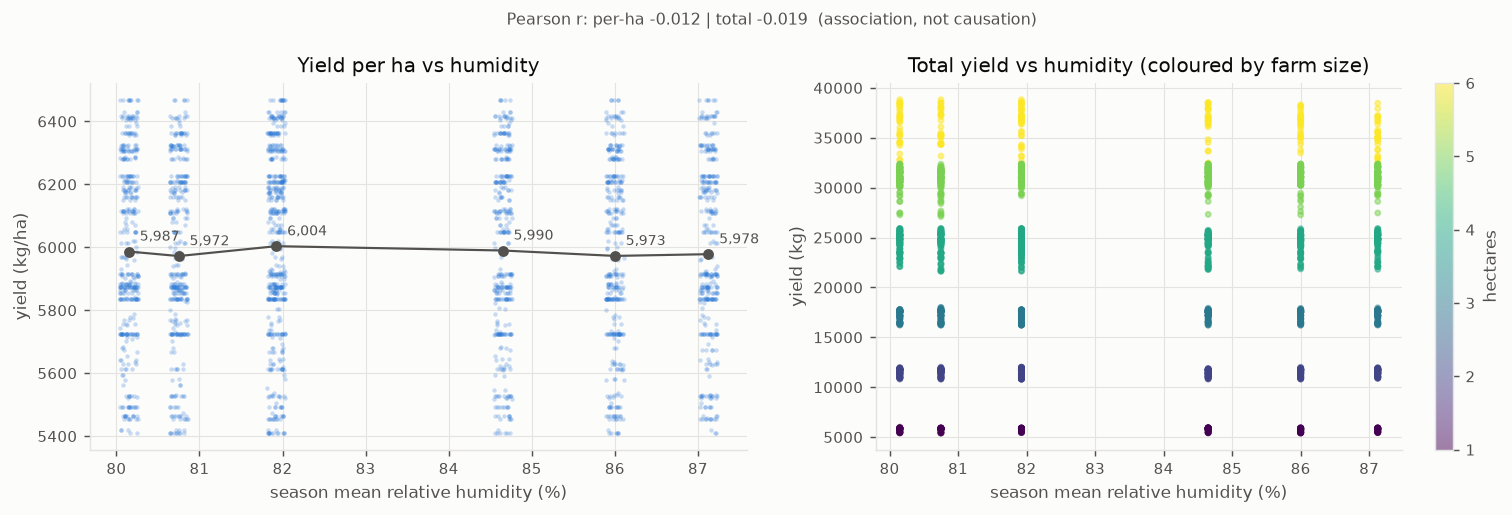

In [16]:
show('eda_yield_vs_humidity.png')

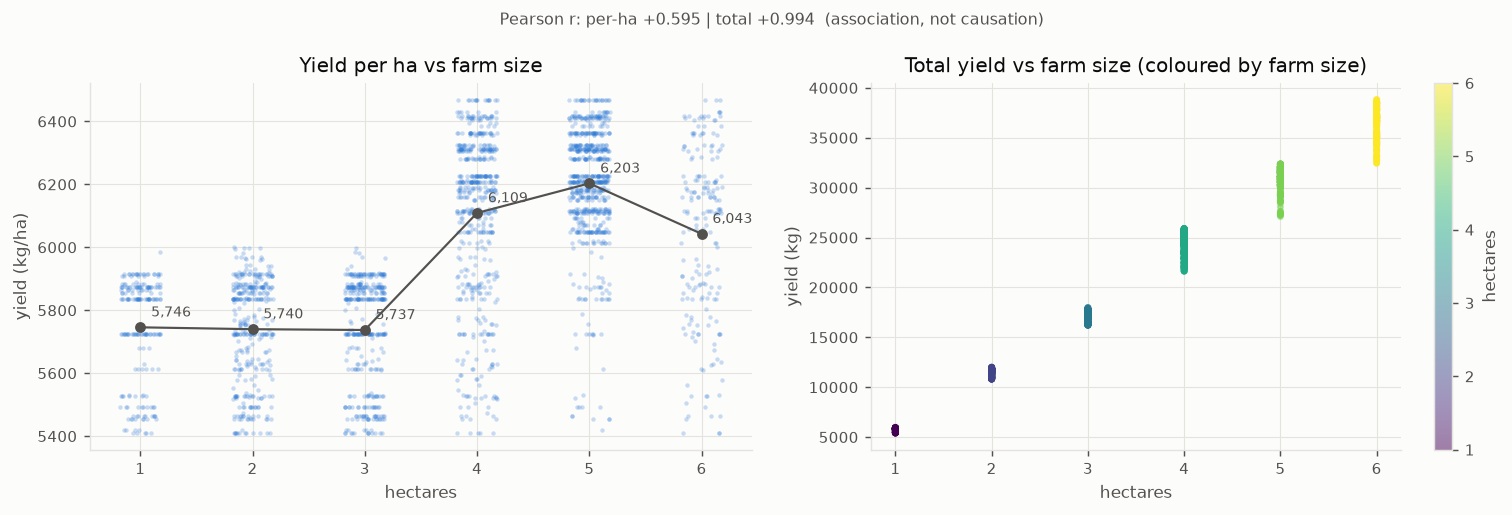

In [17]:
show('eda_yield_vs_hectares.png')

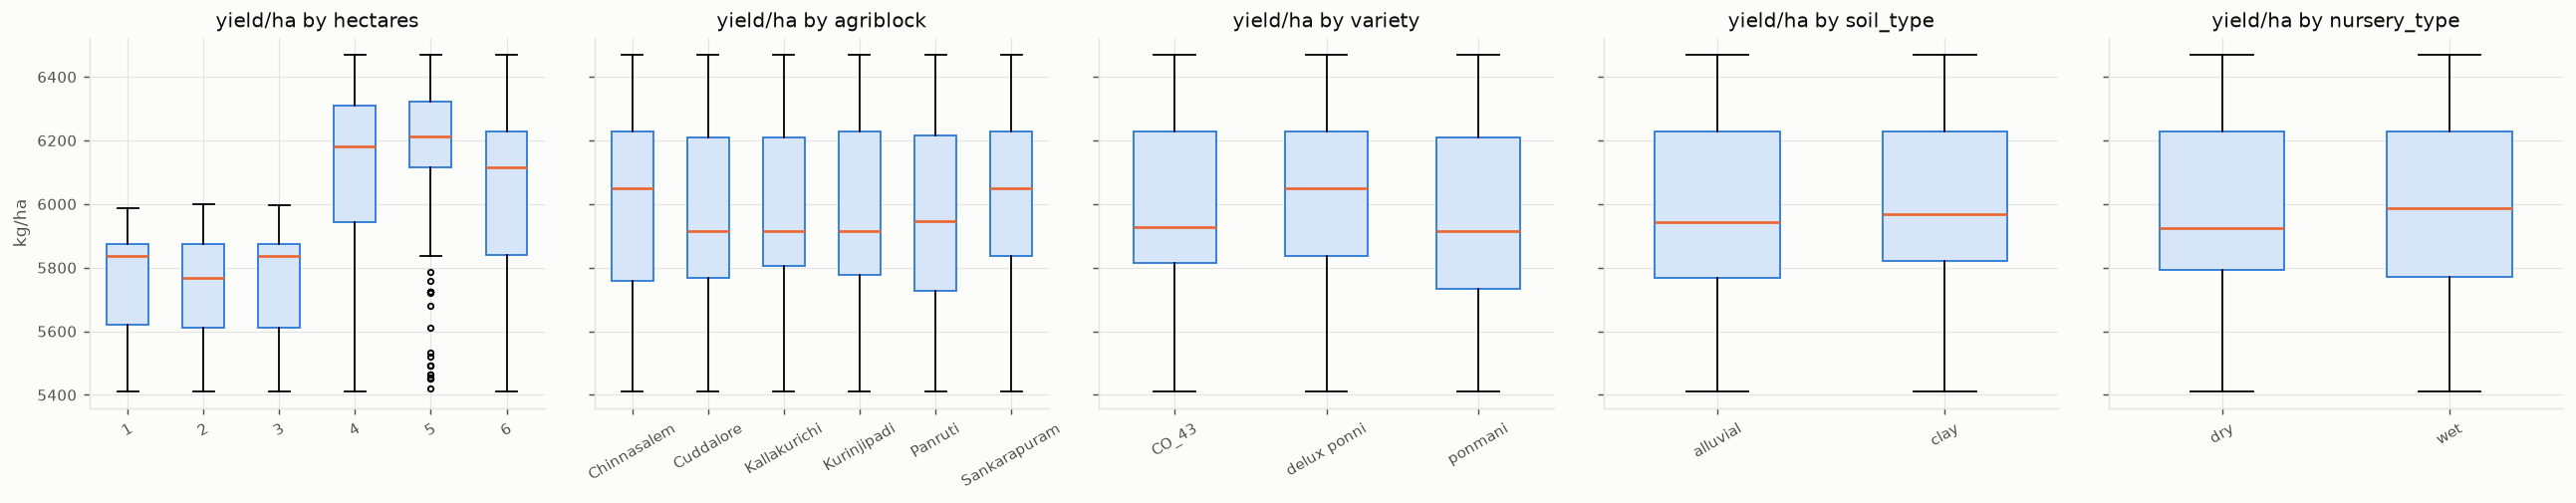

In [18]:
show('eda_categorical_effects.png', 1100)

## Findings

* **Target**: `Paddy yield(in Kg)` — total paddy harvested per farm record, in kg (5,410–38,814). No missing values, no physically invalid values.
* **Feature types**: 44 predictors = 36 numeric + 8 categorical (`Agriblock`, `Variety`, `Soil Types`, `Nursery`, 4× wind direction). Geographic: `Agriblock` (6 blocks of Cuddalore/Kallakurichi districts, Tamil Nadu). **Temporal: none** — the `D1_D30 … D91_D120` columns are crop-stage windows within a season, not calendar time; there is no year/season column.
* **451 exact duplicate rows (16.2%)** → removed before splitting (2,338 rows remain).
* **Farm size drives everything**: all 10 input-quantity columns (seed, DAP, urea, potash, micronutrients, weedicide, pesticide, nursery area, land-prep) are *exactly* `hectares × constant`. Every farm applies identical per-hectare doses, so fertilizer/nitrogen carries **no information beyond farm size**. `corr(yield_kg, hectares) = 0.994` → hectares alone gives R² = 0.989.
* **Weather ≡ location**: all 28 weather columns take exactly one value per agriblock (6 weather profiles total). Weather effects cannot be separated from location effects. `rain + AI` is constant per stage (40 / 458 / 417 / 125 mm), so "AI" is complementary water and adds no information.
* **Post-harvest leakage**: `Trash(in bundles)` is a harvest by-product (r = 0.957 with yield) — excluded. Here it equals hectares × a variety constant (80/90/100 bundles/ha, one exception), so it happens not to leak extra signal, but it would be unavailable at prediction time.
* **Per-hectare yield** (5,410–6,469 kg/ha, mean ≈ 5,985) is the agronomically meaningful quantity. ~41% of its variance occurs between rows with *identical* features → estimated R² ceiling ≈ 0.59.
* EDA associations: per-ha yield is ~5,740 kg/ha for 1–3 ha farms and ~6,050–6,200 for 4–6 ha farms; differences across variety, soil, nursery, block (and therefore weather) are small. These are associations, not causal effects.
